# Does the campaign cause purchases?

This notebook uses the [Criteo Uplift dataset](https://huggingface.co/datasets/criteo/criteo-uplift), a set of real incrementality tests: a random slice of users was withheld from advertising.

The marketing question is easy to get wrong. People who were shown an ad buy more often than people who were not. Ad platforms prefer users who were already likely to buy, so seeing an ad can be a **symptom** of purchase intent. The randomized assignment is the part that can support a causal claim.

| Column | Meaning | Randomized? |
|---|---|---|
| `treatment` | User was eligible to be targeted | Yes |
| `exposure` | User was actually shown an ad | No |
| `visit` | User visited the advertiser site | Outcome |
| `conversion` | User purchased | Outcome |
| `f0`–`f11` | Anonymized pre-treatment features | Covariates |

Two facts drive the statistics. Control users are never exposed (`treatment = 0` implies `exposure = 0`). Conversion is rare (about 0.29%), and about 85% of users were assigned to treatment.

The notebook reports, on the full file:

- absolute and relative conversion lift
- confidence intervals that behave at a rare rate
- four treatment-effect estimates, including the confounded one
- what the 85/15 split did to precision
- expected value of the campaign under assumptions you can edit

A sample is used only for covariate adjustment and for a simple uplift model. Those sections say so.

**License.** CC-BY-NC-SA-4.0. Non-commercial use, with attribution. Cite Diemert, Betlei, Renaudin, and Amini, *A Large Scale Benchmark for Uplift Modeling*, AdKDD / KDD 2018. The v2 file used here is the rebalanced release described in arXiv:2111.10106. Do not commit the data file.

**How to run.** Open this notebook with the kernel named `Python 3.11 (A/B testing)`. The environment lives outside this folder because the folder name contains a colon and Python refuses to create a virtual environment in that path. Run the cells from top to bottom. The first data cell downloads about 300 MB and builds a parquet file. Later runs reuse both.


In [1]:
from pathlib import Path
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    test_proportions_2indep,
)

pd.set_option("display.float_format", lambda v: f"{v:.6g}")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "font.size": 11,
    "axes.titlesize": 13,
})

def find_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "requirements.txt").exists() and (cand / "criteo_incrementality.ipynb").exists():
            return cand
    raise FileNotFoundError("Open and run this notebook from the project directory.")

ROOT = find_root()
DATA = ROOT / "data"
RAW = DATA / "raw"
PARQUET = DATA / "criteo.parquet"
SAMPLE_PARQUET = DATA / "sample.parquet"
DATA.mkdir(parents=True, exist_ok=True)

FEATURES = [f"f{i}" for i in range(12)]
EXPECTED_ROWS = 13_979_592
CARD_VISIT = 0.046992
CARD_CONVERSION = 0.00292
CARD_TREATMENT = 0.85
SAMPLE_N = 800_000
SAMPLE_SEED = 7

print("project:", ROOT)
print("duckdb", duckdb.__version__, "| numpy", np.__version__)


project: /Users/apple/Downloads/My Files/My File/Projects/A:B Testing & Causal Impact Platform
duckdb 1.3.2 | numpy 2.1.3


## Shared arithmetic

Every later section uses these functions. The inputs are counts, so the same math describes a small simulation and the full 14 million-row file.

- **Absolute lift** is a difference of rates: purchases per user in group A minus purchases per user in group B.
- **Relative lift** is that difference as a fraction of the baseline rate.
- The interval for the difference is a Newcombe interval. It is built for two independent proportions and does not rely on the normal approximation that fails when events are rare.
- The interval for relative lift is the Katz interval on the log risk ratio.
- **CACE** (complier average causal effect) divides the intent-to-treat effect by the share of assigned users who were actually exposed. The standard error uses the delta method and the fact that, inside the treated arm, the conversion rate and the exposure rate are estimated from the same people.


In [2]:
def newcombe_diff(k1, n1, k0, n0, alpha=0.05):
    """95% interval for p1 - p0. Returns (estimate, low, high)."""
    estimate = k1 / n1 - k0 / n0
    low, high = confint_proportions_2indep(
        k1, n1, k0, n0, method="newcombe", compare="diff", alpha=alpha,
    )
    return float(estimate), float(low), float(high)


def katz_relative(k1, n1, k0, n0, alpha=0.05):
    """Relative lift p1/p0 - 1, with a Katz interval. Returns (estimate, low, high)."""
    p1 = k1 / n1
    p0 = k0 / n0
    if p1 <= 0 or p0 <= 0 or k1 == 0 or k0 == 0:
        return np.nan, np.nan, np.nan
    log_ratio = np.log(p1 / p0)
    se = np.sqrt((1 - p1) / k1 + (1 - p0) / k0)
    z = stats.norm.ppf(1 - alpha / 2)
    low, high = np.exp(log_ratio - z * se) - 1, np.exp(log_ratio + z * se) - 1
    return float(p1 / p0 - 1), float(low), float(high)


def cace_effect(k_t, n_t, k_c, n_c, k_e, n_e, alpha=0.05):
    """Effect on users the campaign actually reached, under one-sided non-compliance.

    k_e and n_e are conversions and users among the exposed.
    Those exposed users are a subset of the treated arm.
    """
    p_t = k_t / n_t
    p_c = k_c / n_c
    exposure_rate = n_e / n_t
    itt = p_t - p_c
    if exposure_rate <= 0:
        return np.nan, np.nan, np.nan, np.nan
    estimate = itt / exposure_rate
    var_pt = p_t * (1 - p_t) / n_t
    var_pc = p_c * (1 - p_c) / n_c
    var_e = exposure_rate * (1 - exposure_rate) / n_t
    # k_e = sum of (conversion × exposure) inside the treated arm
    cov_pt_e = (k_e / n_t - p_t * exposure_rate) / n_t
    g_pt, g_pc, g_e = 1 / exposure_rate, -1 / exposure_rate, -itt / exposure_rate**2
    variance = (
        g_pt**2 * var_pt
        + g_pc**2 * var_pc
        + g_e**2 * var_e
        + 2 * g_pt * g_e * cov_pt_e
    )
    se = np.sqrt(max(variance, 0.0))
    z = stats.norm.ppf(1 - alpha / 2)
    return float(estimate), float(estimate - z * se), float(estimate + z * se), float(se)


def estimands_from_counts(k_t, n_t, k_c, n_c, k_e, n_e, k_not, n_not):
    """Four answers to 'did the campaign increase purchases?'."""
    rows = []

    def add(name, causal, k1, n1, k0, n0, estimate, low, high, meaning):
        rel, rel_lo, rel_hi = katz_relative(k1, n1, k0, n0)
        rows.append({
            "estimand": name,
            "causal": causal,
            "difference": estimate,
            "diff_low": low,
            "diff_high": high,
            "relative_lift": rel,
            "rel_low": rel_lo,
            "rel_high": rel_hi,
            "meaning": meaning,
        })

    diff, lo, hi = newcombe_diff(k_e, n_e, k_not, n_not)
    add(
        "naive", False, k_e, n_e, k_not, n_not, diff, lo, hi,
        "Exposed versus not exposed. Confounded by who the platform chose to show the ad.",
    )
    diff, lo, hi = newcombe_diff(k_e, n_e, k_c, n_c)
    add(
        "per_protocol", False, k_e, n_e, k_c, n_c, diff, lo, hi,
        "Exposed versus control. Still biased: exposure happened after assignment.",
    )
    diff, lo, hi = newcombe_diff(k_t, n_t, k_c, n_c)
    add(
        "itt", True, k_t, n_t, k_c, n_c, diff, lo, hi,
        "Assigned to the campaign versus withheld. Effect of running the campaign.",
    )
    estimate, lo, hi, _ = cace_effect(k_t, n_t, k_c, n_c, k_e, n_e)
    rel_point = estimate / (k_c / n_c) if k_c else np.nan
    rows.append({
        "estimand": "cace",
        "causal": True,
        "difference": estimate,
        "diff_low": lo,
        "diff_high": hi,
        "relative_lift": rel_point,
        "rel_low": np.nan,
        "rel_high": np.nan,
        "meaning": "Effect on users the campaign could reach. ITT divided by the exposure rate in the treated arm.",
    })
    return pd.DataFrame(rows)


def counts_from_arrays(treatment, exposure, outcome):
    t = np.asarray(treatment).astype(bool)
    e = np.asarray(exposure).astype(bool)
    y = np.asarray(outcome).astype(bool)
    return dict(
        k_t=int(y[t].sum()), n_t=int(t.sum()),
        k_c=int(y[~t].sum()), n_c=int((~t).sum()),
        k_e=int(y[e].sum()), n_e=int(e.sum()),
        k_not=int(y[~e].sum()), n_not=int((~e).sum()),
    )


def show_estimands(frame):
    view = frame.copy()
    view["difference_pp"] = view["difference"] * 100
    view["interval_pp"] = view.apply(
        lambda r: f"[{r['diff_low'] * 100:.4f}, {r['diff_high'] * 100:.4f}]", axis=1,
    )
    view["relative"] = view["relative_lift"].map(lambda v: "—" if pd.isna(v) else f"{v * 100:.1f}%")
    return view[["estimand", "causal", "difference_pp", "interval_pp", "relative", "meaning"]]


## A small world where the mistake is obvious

Before touching Criteo, here is a population we fully control.

Intent varies across users. The platform shows the ad only to treated users with high intent. The ad itself adds one percentage point to the purchase probability. Assignment is random. Exposure is not.

The naive comparison uses exposure. The intent-to-treat comparison uses assignment. The true effect of *running the campaign* is one percentage point times the share of treated users who get the ad, not one percentage point, and not the gap between exposed and unexposed users.


In [3]:
rng = np.random.default_rng(7)
n_sim = 200_000
intent = rng.random(n_sim)
treatment = rng.random(n_sim) < 0.85
exposure = treatment & (intent > 0.60)
baseline = 0.002 + 0.02 * intent
true_exposure_effect = 0.01
conversion = rng.random(n_sim) < (baseline + true_exposure_effect * exposure)

sim_counts = counts_from_arrays(treatment, exposure, conversion)
sim = estimands_from_counts(**sim_counts)
true_itt = true_exposure_effect * exposure[treatment].mean()

print(f"True effect of showing the ad: {true_exposure_effect * 100:.2f} percentage points")
print(f"Share of treated users who see the ad: {exposure[treatment].mean():.1%}")
print(f"True effect of running the campaign (ITT): {true_itt * 100:.2f} percentage points")
print()
show_estimands(sim)


True effect of showing the ad: 1.00 percentage points
Share of treated users who see the ad: 40.0%
True effect of running the campaign (ITT): 0.40 percentage points



,estimand,causal,difference_pp,interval_pp,relative,meaning
0,naive,False,1.90723,"[1.7770, 2.0413]",227.9%,Exposed versus not exposed. Confounded by who the platform chose to show the ad.
1,per_protocol,False,1.61399,"[1.4396, 1.7834]",142.8%,Exposed versus control. Still biased: exposure happened after assignment.
2,itt,True,0.419321,"[0.2802, 0.5480]",37.1%,Assigned to the campaign versus withheld. Effect of running the campaign.
3,cace,True,1.04709,"[0.7134, 1.3808]",92.7%,Effect on users the campaign could reach. ITT divided by the exposure rate in the treated arm.


Read the table against the two true numbers above. The ITT row should land near the true campaign effect. The naive row should be several times larger, because the exposed group is mostly high-intent users. That inflation is the quantity this project exists to measure. The next sections estimate it on the Criteo tests instead of on a simulation.


## Load the file without unpacking it

The gzip is about 300 MB. Unpacked, the CSV is about 3.2 GB. This machine has roughly 17 GB free, so the notebook streams the gzip into parquet and never writes the CSV.

DuckDB does the scan. The result is one row per user, with features stored as 32-bit floats and the four flags stored as small integers.


In [4]:
from huggingface_hub import hf_hub_download

gz_path = Path(hf_hub_download(
    repo_id="criteo/criteo-uplift",
    filename="criteo-research-uplift-v2.1.csv.gz",
    repo_type="dataset",
    local_dir=str(RAW),
))
print("gzip:", gz_path, f"({gz_path.stat().st_size / 1e6:.0f} MB)")

con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
con.execute("SET threads=4")
con.execute("SET memory_limit='6GB'")

if not PARQUET.exists():
    started = time.perf_counter()
    feature_sql = ", ".join(f"{c}::FLOAT AS {c}" for c in FEATURES)
    src = str(gz_path).replace("'", "''")
    dest = str(PARQUET).replace("'", "''")
    con.execute(f"""
        COPY (
            SELECT
                row_number() OVER () AS user_id,
                {feature_sql},
                treatment::UTINYINT AS treatment,
                conversion::UTINYINT AS conversion,
                visit::UTINYINT AS visit,
                exposure::UTINYINT AS exposure
            FROM read_csv('{src}', header=true)
        ) TO '{dest}' (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
    print(f"wrote parquet in {time.perf_counter() - started:.0f}s")
else:
    print("parquet already built")

print(f"parquet size: {PARQUET.stat().st_size / 1e6:.0f} MB")
con.execute(f"CREATE OR REPLACE VIEW users AS SELECT * FROM read_parquet('{str(PARQUET).replace(chr(39), chr(39)+chr(39))}')")
con.execute("SELECT * FROM users LIMIT 3").df()


gzip: /Users/apple/Downloads/My Files/My File/Projects/A:B Testing & Causal Impact Platform/data/raw/criteo-research-uplift-v2.1.csv.gz (311 MB)


parquet already built
parquet size: 124 MB


,user_id,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,371292,21.0282,10.0597,8.21438,4.67988,10.2805,4.11545,-1.28821,4.83381,3.97186,13.1901,5.30037,-0.168679,1,0,0,0
1,371293,23.4767,10.0597,8.21438,4.67988,10.2805,4.11545,-1.28821,4.83381,3.97186,13.1901,5.30037,-0.168679,1,0,0,0
2,371294,24.054,10.0597,8.21438,4.67988,10.2805,4.11545,-5.57641,4.83381,3.97186,13.1901,5.30037,-0.168679,1,0,0,0


## Data contract

These checks are the conditions the later claims rely on.

1. The file has 13,979,592 rows, the count published for v2.
2. The four flags are binary and there are no nulls.
3. No control user is exposed. This is one-sided non-compliance, and it is a fact about the file, not an assumption.
4. Visit and conversion rates are close to the dataset card (0.046992 and 0.00292). The card also says the treatment ratio is 0.85. That figure is rounded. With 14 million rows a chi-square test against exactly 0.85 rejects trivial differences, so the check is the size of the gap, and the chi-square is only a diagnostic.
5. Covariate balance: the standardized difference between arms on each feature. A single coin-flip randomization on 14 million rows would put every value near 0.001. This file pools several tests and then forces the treatment share to 85%, so small residual differences can remain. The usual line for a meaningful imbalance is 0.10. The table is a description, not a reason to throw the file out.
6. Whether every conversion has a visit. The dataset paper says a purchase cannot happen without a visit. We measure it.


In [5]:
feature_nulls = " OR ".join(f"{c} IS NULL" for c in FEATURES)
audit = con.execute(f"""
    SELECT
        COUNT(*) AS n,
        COUNT(*) FILTER (
            WHERE {feature_nulls}
               OR treatment IS NULL OR conversion IS NULL
               OR visit IS NULL OR exposure IS NULL
        ) AS null_rows,
        COUNT(*) FILTER (
            WHERE treatment NOT IN (0, 1) OR conversion NOT IN (0, 1)
               OR visit NOT IN (0, 1) OR exposure NOT IN (0, 1)
        ) AS non_binary,
        COUNT(*) FILTER (WHERE treatment = 0 AND exposure = 1) AS exposed_controls,
        COUNT(*) FILTER (WHERE conversion = 1 AND visit = 0) AS conversion_without_visit,
        SUM(treatment) AS n_treated,
        SUM(1 - treatment) AS n_control,
        SUM(conversion) AS n_conversions,
        SUM(visit) AS n_visits,
        AVG(treatment) AS treatment_ratio,
        AVG(conversion) AS conversion_rate,
        AVG(visit) AS visit_rate,
        AVG(exposure) AS exposure_rate
    FROM users
""").df().iloc[0]

n = int(audit["n"])
ratio = float(audit["treatment_ratio"])
expected_treated = CARD_TREATMENT * n
srm_chi2 = (
    (audit["n_treated"] - expected_treated) ** 2 / expected_treated
    + (audit["n_control"] - (n - expected_treated)) ** 2 / (n - expected_treated)
)
srm_p = float(1 - stats.chi2.cdf(srm_chi2, 1))

mean_bits = ", ".join(
    f"avg({c}) FILTER (WHERE treatment = 1) AS m1_{c}, "
    f"avg({c}) FILTER (WHERE treatment = 0) AS m0_{c}, "
    f"var_samp({c}) FILTER (WHERE treatment = 1) AS v1_{c}, "
    f"var_samp({c}) FILTER (WHERE treatment = 0) AS v0_{c}"
    for c in FEATURES
)
balance_row = con.execute(f"SELECT {mean_bits} FROM users").df().iloc[0]
smd_rows = []
for c in FEATURES:
    pooled = np.sqrt((balance_row[f"v1_{c}"] + balance_row[f"v0_{c}"]) / 2)
    smd = (balance_row[f"m1_{c}"] - balance_row[f"m0_{c}"]) / pooled
    smd_rows.append({"feature": c, "smd": smd})
balance = pd.DataFrame(smd_rows)

gates = pd.DataFrame([
    ["row count is 13,979,592", n == EXPECTED_ROWS, f"{n:,}"],
    ["no nulls", int(audit["null_rows"]) == 0, int(audit["null_rows"])],
    ["flags are binary", int(audit["non_binary"]) == 0, int(audit["non_binary"])],
    ["no exposed controls", int(audit["exposed_controls"]) == 0, int(audit["exposed_controls"])],
    ["treatment ratio within 0.5 points of 0.85", abs(ratio - CARD_TREATMENT) < 0.005, f"{ratio:.6f}"],
    ["visit rate within 1% of the card", abs(audit["visit_rate"] - CARD_VISIT) / CARD_VISIT < 0.01, f"{audit['visit_rate']:.6f}"],
    ["conversion rate within 1% of the card", abs(audit["conversion_rate"] - CARD_CONVERSION) / CARD_CONVERSION < 0.01, f"{audit['conversion_rate']:.6f}"],
])
gates.columns = ["check", "pass", "detail"]

max_smd = float(balance["smd"].abs().max())
print("chi-square against exactly 0.85:", f"{srm_chi2:.1f}", "| p-value", f"{srm_p:.3g}")
print("conversions with no visit:", int(audit["conversion_without_visit"]))
print("exposure rate in the whole file:", f"{audit['exposure_rate']:.4%}")
print(f"Largest |standardized difference| across f0–f11: {max_smd:.3f}")
print("A pure coin flip on this many rows would land near 0.001. The 0.10 line is where an imbalance starts to matter. The next cell lists every feature.")
if not bool(gates["pass"].all()):
    display(gates)
    raise RuntimeError("A data-contract check failed. Later cells would be describing a different experiment.")
gates


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

chi-square against exactly 0.85: 0.0 | p-value 0.999
conversions with no visit: 0
exposure rate in the whole file: 3.0631%
Largest |standardized difference| across f0–f11: 0.049
A pure coin flip on this many rows would land near 0.001. The 0.10 line is where an imbalance starts to matter. The next cell lists every feature.


,check,pass,detail
0,"row count is 13,979,592",True,"13,979,592"
1,no nulls,True,0
2,flags are binary,True,0
3,no exposed controls,True,0
4,treatment ratio within 0.5 points of 0.85,True,0.850000
5,visit rate within 1% of the card,True,0.046992
6,conversion rate within 1% of the card,True,0.002917


In [6]:
balance.sort_values("smd", key=lambda s: s.abs(), ascending=False)


,feature,smd
3,f3,-0.0488363
6,f6,-0.0404481
5,f5,-0.0305568
9,f9,0.0240011
1,f1,0.0239944
8,f8,-0.0224333
7,f7,0.0212695
10,f10,0.0105635
4,f4,0.00796566
0,f0,-0.00686562


## The four estimates on the real test

The cell below is one SQL aggregation. It counts users and purchases in each assignment-by-exposure cell, then hands those counts to the functions from the top of the notebook.

Use **conversion** to answer the purchase question. **Visit** is the step before a purchase. It is less rare, so its intervals are tighter, and it is a useful check that the pattern is not an artifact of a few thousand purchases.


In [7]:
cells = con.execute("""
    SELECT
        treatment,
        exposure,
        COUNT(*) AS users,
        SUM(conversion) AS conversions,
        SUM(visit) AS visits
    FROM users
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()
cells


,treatment,exposure,users,conversions,visits
0,0,0,2096937,4063,80105
1,1,0,11454443,13680,399314
2,1,1,428212,23031,177510


In [8]:
def counts_for(outcome_col):
    treated = cells[cells["treatment"] == 1]
    control = cells[cells["treatment"] == 0]
    exposed = cells[cells["exposure"] == 1]
    unexposed = cells[cells["exposure"] == 0]
    return dict(
        k_t=int(treated[outcome_col].sum()),
        n_t=int(treated["users"].sum()),
        k_c=int(control[outcome_col].sum()),
        n_c=int(control["users"].sum()),
        k_e=int(exposed[outcome_col].sum()),
        n_e=int(exposed["users"].sum()),
        k_not=int(unexposed[outcome_col].sum()),
        n_not=int(unexposed["users"].sum()),
    )

conversion_counts = counts_for("conversions")
visit_counts = counts_for("visits")
conversion_fx = estimands_from_counts(**conversion_counts)
visit_fx = estimands_from_counts(**visit_counts)

print("Conversion — purchases")
display(show_estimands(conversion_fx))
print("Visit — site visits")
display(show_estimands(visit_fx))

itt = conversion_fx.set_index("estimand").loc["itt"]
naive = conversion_fx.set_index("estimand").loc["naive"]
print(
    f"Bias factor on purchases (naive ÷ ITT): {naive['difference'] / itt['difference']:.2f}. "
    f"The exposure comparison is {naive['difference'] * 100:.4f} percentage points. "
    f"The assignment comparison is {itt['difference'] * 100:.4f} percentage points."
)


Conversion — purchases


,estimand,causal,difference_pp,interval_pp,relative,meaning
0,naive,False,5.24748,"[5.1803, 5.3155]",4007.8%,Exposed versus not exposed. Confounded by who the platform chose to show the ad.
1,per_protocol,False,5.18465,"[5.1172, 5.2529]",2675.8%,Exposed versus control. Still biased: exposure happened after assignment.
2,itt,True,0.115187,"[0.1084, 0.1219]",59.4%,Assigned to the campaign versus withheld. Effect of running the campaign.
3,cace,True,3.19639,"[3.0100, 3.3828]",1649.7%,Effect on users the campaign could reach. ITT divided by the exposure rate in the treated arm.


Visit — site visits


,estimand,causal,difference_pp,interval_pp,relative,meaning
0,naive,False,37.916,"[37.7682, 38.0639]",1071.7%,Exposed versus not exposed. Confounded by who the platform chose to show the ad.
1,per_protocol,False,37.6337,"[37.4839, 37.7835]",985.1%,Exposed versus control. Still biased: exposure happened after assignment.
2,itt,True,1.03424,"[1.0055, 1.0628]",27.1%,Assigned to the campaign versus withheld. Effect of running the campaign.
3,cace,True,28.6996,"[27.9112, 29.4880]",751.3%,Effect on users the campaign could reach. ITT divided by the exposure rate in the treated arm.


Bias factor on purchases (naive ÷ ITT): 45.56. The exposure comparison is 5.2475 percentage points. The assignment comparison is 0.1152 percentage points.


### How to read the intervals

The intervals on the naive and per-protocol rows are real statements about sampling noise. They are not causal uncertainty. A narrow interval around a biased comparison is a precise answer to the wrong question.

The ITT interval is the one that matches the decision "keep running this kind of campaign for everyone we assigned." The CACE interval matches "what happens to people the campaign actually reaches." CACE is larger than ITT when some assigned users never see the ad, because the campaign effect is spread over people who were never shown it.

CACE needs one assumption the file cannot prove: a user who would not have been shown the ad is unaffected by having been *assignable*. That is the exclusion restriction. The zero exposed controls support the one-sided compliance half of the argument. They do not prove exclusion.

Relative lift for CACE is the complier effect divided by the control purchase rate. It has no Katz interval here, because CACE is a ratio of two estimates and that extra step is omitted on purpose. The absolute interval is the one to use.


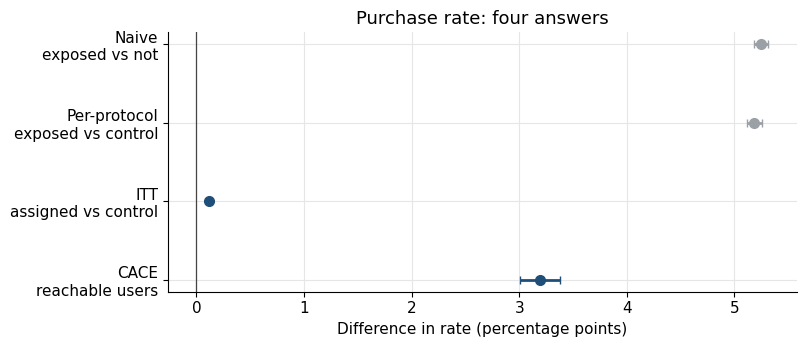

Blue intervals are the causal estimands. Gray intervals are sampling noise around a biased comparison.


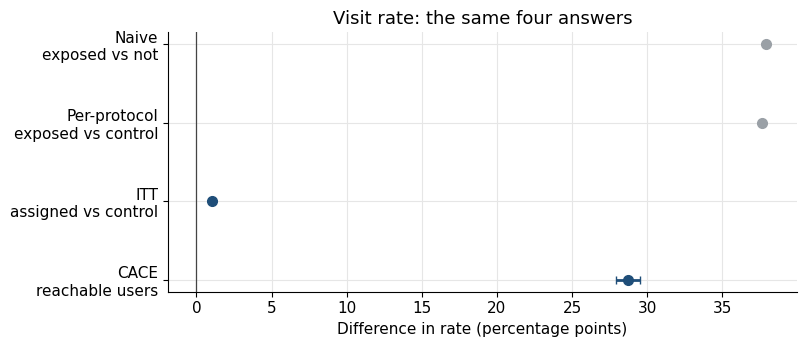

Visits are more common, so this picture is less sensitive to a handful of purchases.


In [9]:
def forest(frame, title, path_note):
    order = ["naive", "per_protocol", "itt", "cace"]
    labels = {
        "naive": "Naive\nexposed vs not",
        "per_protocol": "Per-protocol\nexposed vs control",
        "itt": "ITT\nassigned vs control",
        "cace": "CACE\nreachable users",
    }
    plot_df = frame.set_index("estimand").loc[order]
    y = np.arange(len(order))
    estimate = plot_df["difference"] * 100
    low = plot_df["diff_low"] * 100
    high = plot_df["diff_high"] * 100
    colors = ["#9aa0a6" if not flag else "#1f4e79" for flag in plot_df["causal"]]
    fig, ax = plt.subplots(figsize=(8.2, 3.6))
    ax.axvline(0, color="#444444", linewidth=0.9)
    for i, name in enumerate(order):
        ax.errorbar(
            estimate.loc[name], y[i],
            xerr=[[estimate.loc[name] - low.loc[name]], [high.loc[name] - estimate.loc[name]]],
            fmt="o", color=colors[i], ecolor=colors[i], elinewidth=2, capsize=3, markersize=7,
        )
    ax.set_yticks(y)
    ax.set_yticklabels([labels[name] for name in order])
    ax.set_xlabel("Difference in rate (percentage points)")
    ax.set_title(title)
    ax.invert_yaxis()
    fig.tight_layout()
    plt.show()
    print(path_note)

forest(conversion_fx, "Purchase rate: four answers", "Blue intervals are the causal estimands. Gray intervals are sampling noise around a biased comparison.")
forest(visit_fx, "Visit rate: the same four answers", "Visits are more common, so this picture is less sensitive to a handful of purchases.")


## A second route to the same ITT

The difference in purchase rates between assigned and withheld users is an ordinary regression coefficient. On the full file:

`conversion ~ treatment`

with a robust (HC1) variance is the same point estimate as the risk difference above. Computing it from the counts, rather than by loading 14 million rows into a model object, keeps the check exact.

Lin's estimator then adds the pre-treatment features, centered, and their interactions with treatment. Under randomization the treatment coefficient stays unbiased, and the covariates can shrink the standard error. The balance table is not perfectly flat — the largest gap is a few hundredths of a standard deviation — so this fit is also a check that those leftover differences are not the purchase result. There is no pre-period purchase column, so this is the available version of variance reduction. It is fit on a repeatable sample of 800,000 users because a robust regression on the full file is an unnecessary memory cost. The sample answer is a precision check. The full-file ITT above is the campaign answer.


In [10]:
# Full-file OLS point estimate from the two arm means. HC1 SE for a saturated binary treatment
# equals the usual unpooled SE of a difference in proportions.
p_t = conversion_counts["k_t"] / conversion_counts["n_t"]
p_c = conversion_counts["k_c"] / conversion_counts["n_c"]
itt_ols = p_t - p_c
se_ols = np.sqrt(p_t * (1 - p_t) / conversion_counts["n_t"] + p_c * (1 - p_c) / conversion_counts["n_c"])
z = stats.norm.ppf(0.975)
print("Full-file purchase ITT")
print(f"  risk difference {itt_ols:.8f}")
print(f"  HC1-equivalent SE {se_ols:.8f}")
print(f"  normal 95% interval [{itt_ols - z * se_ols:.8f}, {itt_ols + z * se_ols:.8f}]")
newcombe_itt = conversion_fx.set_index("estimand").loc["itt"]
print(f"  Newcombe interval     [{newcombe_itt['diff_low']:.8f}, {newcombe_itt['diff_high']:.8f}]")

pvalue = test_proportions_2indep(
    conversion_counts["k_t"], conversion_counts["n_t"],
    conversion_counts["k_c"], conversion_counts["n_c"],
    method="wald", compare="diff",
)
print("  two-proportion test p-value:", f"{float(pvalue.pvalue):.4g}")

if SAMPLE_PARQUET.exists():
    sample = pd.read_parquet(SAMPLE_PARQUET)
    print("loaded saved sample", f"{len(sample):,}")
else:
    started = time.perf_counter()
    sample = con.execute(f"""
        SELECT treatment, conversion, visit, {", ".join(FEATURES)}
        FROM users
        TABLESAMPLE RESERVOIR ({SAMPLE_N} ROWS) REPEATABLE ({SAMPLE_SEED})
    """).df()
    sample.to_parquet(SAMPLE_PARQUET, index=False)
    print(f"drew {len(sample):,} rows in {time.perf_counter() - started:.0f}s")

def lin_versus_unadjusted(frame, outcome):
    y = frame[outcome].astype(float)
    treatment_col = frame["treatment"].astype(float)
    treatment_col.name = "treatment"
    centered = frame[FEATURES].astype(float)
    centered = centered - centered.mean()
    interacted = centered.mul(treatment_col, axis=0)
    interacted.columns = [f"{c}_x_treatment" for c in FEATURES]
    unadjusted = sm.OLS(y, sm.add_constant(treatment_col, has_constant="add")).fit(cov_type="HC1")
    design = pd.concat([treatment_col, centered, interacted], axis=1)
    adjusted = sm.OLS(y, sm.add_constant(design, has_constant="add")).fit(cov_type="HC1")
    return pd.DataFrame([
        {
            "outcome": outcome,
            "estimator": "unadjusted",
            "estimate": unadjusted.params["treatment"],
            "se": unadjusted.bse["treatment"],
        },
        {
            "outcome": outcome,
            "estimator": "lin",
            "estimate": adjusted.params["treatment"],
            "se": adjusted.bse["treatment"],
        },
    ])

lin_table = pd.concat([
    lin_versus_unadjusted(sample, "conversion"),
    lin_versus_unadjusted(sample, "visit"),
], ignore_index=True)
lin_table["se_vs_unadjusted"] = lin_table.groupby("outcome")["se"].transform(lambda s: s / s.iloc[0])
lin_table


Full-file purchase ITT
  risk difference 0.00115187
  HC1-equivalent SE 0.00003437
  normal 95% interval [0.00108451, 0.00121924]
  Newcombe interval     [0.00108377, 0.00121852]
  two-proportion test p-value: 3.194e-246


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

drew 800,000 rows in 11s


,outcome,estimator,estimate,se,se_vs_unadjusted
0,conversion,unadjusted,0.00261817,0.000337691,1
1,conversion,lin,0.00174579,0.000457567,1.35499
2,visit,unadjusted,-0.0103497,0.00144989,1
3,visit,lin,0.00380689,0.000960231,0.662279


## Was 85/15 a costly design?

Advertisers keep the control group small because withheld users are unsold impressions. For a difference in rates, precision depends on both arms. The scarce arm dominates the standard error.

The minimum detectable effect below uses the published conversion rate as the baseline, a two-sided 5% test, and 80% power. It answers a design question: if the only difference between arms were noise around that baseline, how large a gap could this sample reliably detect?


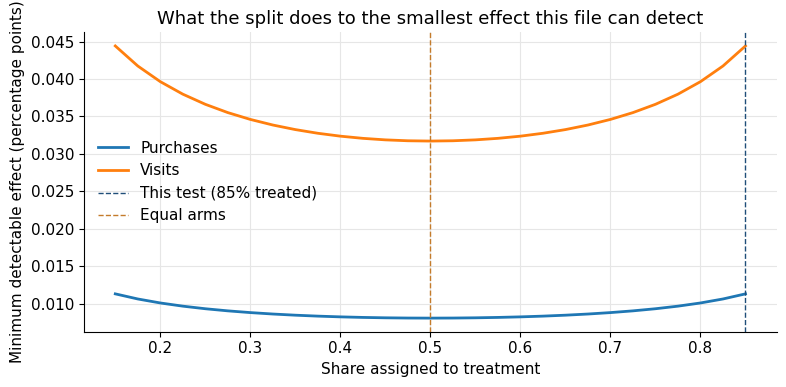

,outcome,baseline_rate,mde_at_this_split,mde_at_50_50,this_split_over_equal
0,conversion,0.00291668,0.000113165,8.08159e-05,1.40028
1,visit,0.046992,0.000444081,0.000317137,1.40028


In [11]:
def se_of_difference(baseline, n, treated_share):
    n_t = n * treated_share
    n_c = n * (1 - treated_share)
    return np.sqrt(baseline * (1 - baseline) * (1 / n_t + 1 / n_c))


def minimum_detectable_effect(baseline, n, treated_share, alpha=0.05, power=0.80):
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return z * se_of_difference(baseline, n, treated_share)

n_users = int(audit["n"])
shares = np.linspace(0.15, 0.85, 29)
fig, ax = plt.subplots(figsize=(8, 4))
for baseline, label in [(CARD_CONVERSION, "Purchases"), (CARD_VISIT, "Visits")]:
    mde_pp = [minimum_detectable_effect(baseline, n_users, s) * 100 for s in shares]
    ax.plot(shares, mde_pp, label=label, linewidth=2)
ax.axvline(0.85, color="#1f4e79", linestyle="--", linewidth=1, label="This test (85% treated)")
ax.axvline(0.50, color="#c47b2b", linestyle="--", linewidth=1, label="Equal arms")
ax.set_xlabel("Share assigned to treatment")
ax.set_ylabel("Minimum detectable effect (percentage points)")
ax.set_title("What the split does to the smallest effect this file can detect")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

design = []
for name, baseline in [("conversion", float(audit["conversion_rate"])), ("visit", float(audit["visit_rate"]))]:
    mde_85 = minimum_detectable_effect(baseline, n_users, float(audit["treatment_ratio"]))
    mde_50 = minimum_detectable_effect(baseline, n_users, 0.50)
    design.append({
        "outcome": name,
        "baseline_rate": baseline,
        "mde_at_this_split": mde_85,
        "mde_at_50_50": mde_50,
        "this_split_over_equal": mde_85 / mde_50,
    })
pd.DataFrame(design)


The observed purchase ITT can now be compared with that minimum detectable effect. An estimate smaller than the MDE can still be real. It means a test of this shape was not built to detect an effect that small with 80% power. Read the confidence interval, not a pass/fail against the MDE.

`statsmodels` also offers sample-size formulas based on the arcsine transformation of two proportions. The cell prints that sample size for a lift equal to the MDE we just computed, as a check that the normal approximation and the library formula are describing the same experiment.


In [12]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

observed = abs(float(itt["difference"]))
mde_conv = float(pd.DataFrame(design).set_index("outcome").loc["conversion", "mde_at_this_split"])
print(f"Observed |purchase ITT|: {observed * 100:.4f} percentage points")
print(f"MDE at this split:       {mde_conv * 100:.4f} percentage points")

p0 = float(audit["conversion_rate"])
p1 = p0 + mde_conv
effect = proportion_effectsize(p1, p0)
# ratio = n_control / n_treated. This test has treatment share r, so n_c / n_t = (1-r) / r.
r = float(audit["treatment_ratio"])
n_required = NormalIndPower().solve_power(
    effect_size=effect, alpha=0.05, power=0.80, ratio=(1 - r) / r, alternative="two-sided",
)
# solve_power returns the size of group 1. Group 1 is the treated arm because
# proportion_effectsize(p1, p0) was built with p1 as the treated rate.
total_required = n_required * (1 + (1 - r) / r)
print(f"statsmodels total sample size for that MDE, at this split: {total_required:,.0f} users")
print(f"users in the file: {n_users:,}")


Observed |purchase ITT|: 0.1152 percentage points
MDE at this split:       0.0113 percentage points
statsmodels total sample size for that MDE, at this split: 14,248,659 users
users in the file: 13,979,592


## What the campaign is worth

The file has no prices and no ad costs. The dollar figures below are a calculator on top of the causal estimate. Change `MARGIN` and `CPM` and rerun the cell.

The population is the treated arm: the question is the value of having assigned those users to the campaign rather than withholding them.

- Incremental purchases = purchase ITT × number of treated users.
- The same total equals CACE × number of exposed users. One effect is spread over everyone assigned. The other is concentrated on people who saw the ad. The count of extra purchases is the same.
- Spend = exposed users × CPM / 1000. This charges only for ads actually shown.
- Expected value = incremental purchases × margin − spend. The interval moves only the ITT. Spend and margin are treated as known inputs.
- The exposure-based revenue credits every purchase by an exposed user to the ad. That is the number a last-click report resembles. It is not incremental.

Absolute rates in this file are not Criteo's live rates. The dataset was sub-sampled non-uniformly so the original incrementality could not be read off the file. Use the dollars as a way to carry the causal gap into a budget conversation, not as a forecast of Criteo's revenue.


Treated users: 11,882,655 | Exposed users: 428,212 | Exposure rate if assigned: 3.6%
Extra purchases from assignment: 13,687  (interval 12,878 to 14,479)
Same total via CACE × exposed users: 13,687
Spend at $8.00 CPM: $3,426
Expected value at $40.00 margin: $544,067  (interval $511,695 to $575,744)
Breakeven margin: $0.25 per purchase
Breakeven CPM, holding this margin: $1278.55
Incremental ROAS: 159.82
Revenue if every exposed purchase is credited to the ad: $921,240


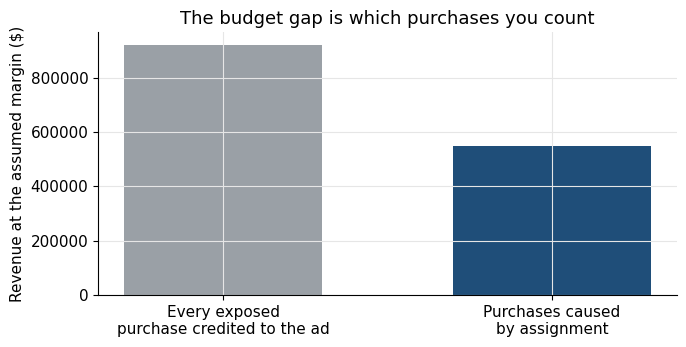

In [13]:
MARGIN = 40.0   # gross profit per purchase, in dollars. An assumption.
CPM = 8.0       # cost per 1,000 exposures, in dollars. An assumption.

n_t = conversion_counts["n_t"]
n_e = conversion_counts["n_e"]
k_e = conversion_counts["k_e"]
itt_hat = float(itt["difference"])
itt_low = float(itt["diff_low"])
itt_high = float(itt["diff_high"])
cace_hat = float(conversion_fx.set_index("estimand").loc["cace", "difference"])

incremental = itt_hat * n_t
incremental_low = itt_low * n_t
incremental_high = itt_high * n_t
incremental_from_cace = cace_hat * n_e
spend = n_e * CPM / 1000
ev = incremental * MARGIN - spend
ev_low = incremental_low * MARGIN - spend
ev_high = incremental_high * MARGIN - spend

exposed_purchases = k_e
credited_revenue = exposed_purchases * MARGIN
incremental_revenue = incremental * MARGIN

print(f"Treated users: {n_t:,} | Exposed users: {n_e:,} | Exposure rate if assigned: {n_e / n_t:.1%}")
print(f"Extra purchases from assignment: {incremental:,.0f}  (interval {incremental_low:,.0f} to {incremental_high:,.0f})")
print(f"Same total via CACE × exposed users: {incremental_from_cace:,.0f}")
print(f"Spend at ${CPM:.2f} CPM: ${spend:,.0f}")
print(f"Expected value at ${MARGIN:.2f} margin: ${ev:,.0f}  (interval ${ev_low:,.0f} to ${ev_high:,.0f})")
if incremental > 0:
    print(f"Breakeven margin: ${spend / incremental:.2f} per purchase")
    print(f"Breakeven CPM, holding this margin: ${incremental * MARGIN / (n_e / 1000):.2f}")
print(f"Incremental ROAS: {incremental_revenue / spend:.2f}")
print(f"Revenue if every exposed purchase is credited to the ad: ${credited_revenue:,.0f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(
    ["Every exposed\npurchase credited to the ad", "Purchases caused\nby assignment"],
    [credited_revenue, incremental_revenue],
    color=["#9aa0a6", "#1f4e79"],
    width=0.6,
)
ax.set_ylabel("Revenue at the assumed margin ($)")
ax.set_title("The budget gap is which purchases you count")
fig.tight_layout()
plt.show()


## Who moves, if anyone

The average effect can hide a group the campaign persuades and a group it does not. A T-learner fits one purchase model on assigned users and another on withheld users. The difference in predicted probabilities, at a user's features, is a predicted individual effect.

This fit uses the 800,000-row sample, with a 30% holdout. The features are anonymized projections, so a high-uplift decile cannot be described as "frequent buyers" or any other business segment. The useful question is narrower: if we rank the holdout by predicted effect, do the top ranks show a larger observed assignment effect than the bottom ranks, and larger than ranking at random?

The bands on the decile chart are Wald intervals. Several deciles contain few purchases, so a wiggly chart is expected. The Qini curve accumulates extra purchases as we include more of the ranking. Its band resamples the holdout and does not refit the model, so it is uncertainty about this evaluation set, not about training.


fit both arms in 3s
train purchases: treated 2500 | control 24


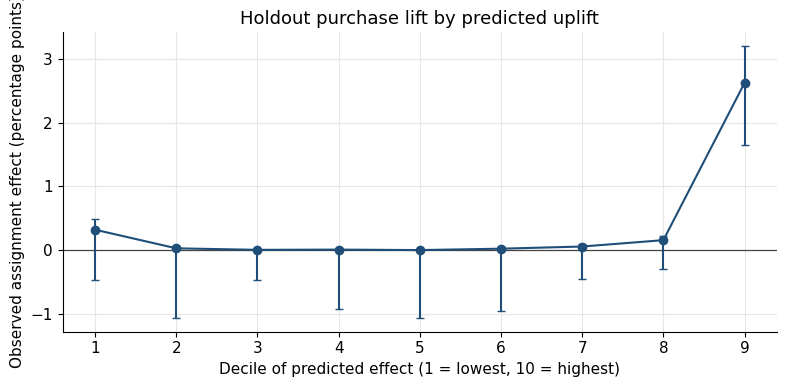

,decile,users,predicted_uplift,observed_lift,low,high,purchases
0,1,26765,-0.00260149,0.00323345,-0.00464768,0.00490729,130
1,2,22084,-0.000427265,0.000322046,-0.0105974,0.00066467,7
2,3,49388,-0.000211168,8.23588e-05,-0.00458077,0.000211765,4
3,4,25198,-0.000183655,0.000121036,-0.00911711,0.000355832,3
4,5,21518,-0.000160322,4.7259e-05,-0.0105692,0.000267669,1
5,6,23088,-0.00013374,0.000264364,-0.00944123,0.000576701,6
6,7,23961,2.73514e-05,0.00060298,-0.0045464,0.00101196,14
7,8,23998,0.000942863,0.00159855,-0.00291134,0.00220248,37
8,9,24000,0.0256219,0.0261931,0.0164194,0.0319842,880


In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

model_frame = sample.copy()
strata = model_frame["treatment"].astype(str) + "_" + model_frame["conversion"].astype(str)
train, holdout = train_test_split(
    model_frame, test_size=0.30, random_state=SAMPLE_SEED, stratify=strata,
)

def fit_arm(frame, treated):
    arm = frame[frame["treatment"] == treated]
    model = HistGradientBoostingClassifier(
        max_depth=3,
        max_iter=80,
        learning_rate=0.08,
        min_samples_leaf=200,
        random_state=SAMPLE_SEED,
    )
    model.fit(arm[FEATURES], arm["conversion"].astype(int))
    return model

started = time.perf_counter()
model_treated = fit_arm(train, 1)
model_control = fit_arm(train, 0)
print(f"fit both arms in {time.perf_counter() - started:.0f}s")
print(
    "train purchases: treated",
    int(train.loc[train.treatment == 1, "conversion"].sum()),
    "| control",
    int(train.loc[train.treatment == 0, "conversion"].sum()),
)

scores = (
    model_treated.predict_proba(holdout[FEATURES])[:, 1]
    - model_control.predict_proba(holdout[FEATURES])[:, 1]
)
holdout = holdout.copy()
holdout["score"] = scores
holdout["decile"] = pd.qcut(holdout["score"], 10, labels=False, duplicates="drop")

decile_rows = []
for decile, part in holdout.groupby("decile"):
    k_t = int(part.loc[part.treatment == 1, "conversion"].sum())
    n_t = int((part.treatment == 1).sum())
    k_c = int(part.loc[part.treatment == 0, "conversion"].sum())
    n_c = int((part.treatment == 0).sum())
    if n_t == 0 or n_c == 0:
        continue
    diff, low, high = newcombe_diff(k_t, n_t, k_c, n_c)
    decile_rows.append({
        "decile": int(decile) + 1,
        "users": len(part),
        "predicted_uplift": part["score"].mean(),
        "observed_lift": diff,
        "low": low,
        "high": high,
        "purchases": k_t + k_c,
    })
deciles = pd.DataFrame(decile_rows).sort_values("decile")

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color="#444444", linewidth=0.9)
ax.errorbar(
    deciles["decile"], deciles["observed_lift"] * 100,
    yerr=[
        (deciles["observed_lift"] - deciles["low"]) * 100,
        (deciles["high"] - deciles["observed_lift"]) * 100,
    ],
    fmt="o-", color="#1f4e79", capsize=3,
)
ax.set_xticks(deciles["decile"])
ax.set_xlabel("Decile of predicted effect (1 = lowest, 10 = highest)")
ax.set_ylabel("Observed assignment effect (percentage points)")
ax.set_title("Holdout purchase lift by predicted uplift")
fig.tight_layout()
plt.show()
deciles


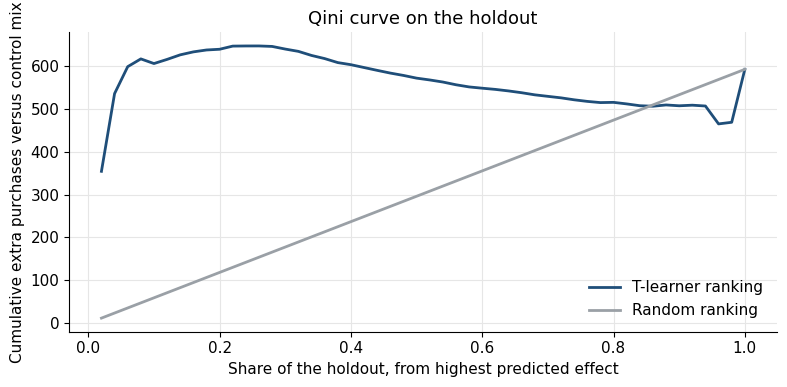

Area under the model curve: 555.4
Area under the random line: 296.0
Holdout-resample band for the model area: [362.4, 777.9]
The ranking beats random targeting on this holdout, including the resample band.


In [15]:
def qini_curve(frame, score, steps=50):
    ranked = frame.assign(score=score).sort_values("score", ascending=False)
    n = len(ranked)
    treated = ranked["treatment"].to_numpy() == 1
    purchased = ranked["conversion"].to_numpy() == 1
    fractions, model_values, random_values = [], [], []
    total_t = int(treated.sum())
    total_c = n - total_t
    total_gain = purchased[treated].sum() - purchased[~treated].sum() * (total_t / total_c)
    for i in range(1, steps + 1):
        cut = int(np.ceil(n * i / steps))
        t = treated[:cut]
        y = purchased[:cut]
        n_t = int(t.sum())
        n_c = cut - n_t
        if n_t == 0 or n_c == 0:
            continue
        gain = y[t].sum() - y[~t].sum() * (n_t / n_c)
        fractions.append(cut / n)
        model_values.append(gain)
        random_values.append(total_gain * (cut / n))
    return np.array(fractions), np.array(model_values), np.array(random_values)


def curve_area(fractions, values):
    return float(np.trapezoid(values, fractions))

fractions, model_q, random_q = qini_curve(holdout, holdout["score"].to_numpy())
rng = np.random.default_rng(SAMPLE_SEED)
areas = []
idx = np.arange(len(holdout))
for _ in range(40):
    draw = holdout.iloc[rng.choice(idx, size=len(idx), replace=True)]
    f, q, _ = qini_curve(draw, draw["score"].to_numpy())
    areas.append(curve_area(f, q))
area_model = curve_area(fractions, model_q)
area_random = curve_area(fractions, random_q)
area_low, area_high = np.percentile(areas, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fractions, model_q, color="#1f4e79", linewidth=2, label="T-learner ranking")
ax.plot(fractions, random_q, color="#9aa0a6", linewidth=2, label="Random ranking")
ax.set_xlabel("Share of the holdout, from highest predicted effect")
ax.set_ylabel("Cumulative extra purchases versus control mix")
ax.set_title("Qini curve on the holdout")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"Area under the model curve: {area_model:.1f}")
print(f"Area under the random line: {area_random:.1f}")
print(f"Holdout-resample band for the model area: [{area_low:.1f}, {area_high:.1f}]")
if area_low > area_random:
    print("The ranking beats random targeting on this holdout, including the resample band.")
else:
    print(
        "The ranking does not clear the random line once holdout noise is included. "
        "With a purchase rate near 0.3% and a few hundred control purchases in the sample, "
        "that is a weak sample for heterogeneity, not a finding that every user responds the same way."
    )


## What these results can support

Believe the full-file comparison of **assignment**, with the Newcombe interval, as the effect of running the campaign on purchases. Put the exposure comparison next to it and keep the ratio. That ratio is how far a report that conditions on seeing the ad moves away from the experiment.

Use CACE when the decision is about people who can actually be shown the ad, and state the exclusion restriction next to the number. Use the dollar cell only after you replace the margin and CPM with your own. Use the decile chart as an exploratory check. The features have no business names, the evaluation sample is thin on purchases, and a model that fails to beat random targeting is an acceptable result.

The file does not contain a timestamp, a price, or the original incrementality level. Sequential "peeking" and a live return on ad spend are outside what this dataset can decide.
